# 10. Calibration exponent against comparison exponent

**Question.** The calibration exponent γ_cal (Table 1) and the exponent γ̂ measured
with the comparison settings differ by up to 0.3. Where does the gap come from, and does
it change the conclusions? Are the ranks of Table 2 stable over realisations?

**Data.** The nine datasets, cache of `scripts/compute_all.py`.
**Outputs.** `out/10_gamma_consistency.csv`, `out/10_mixture_realisations.csv`.
**Paper.** Sec. 4.2 (exponent of the mixture, ranks over 10 realisations) and
Limitations.

| | γ_cal (Sec. 3.2) | γ̂ (Sec. 4.1) |
|---|---|---|
| code | `methods_two_point_correlation`, `calibration.py` | `synthesis_utils.compute_2pcf_norm` |
| nodes | complete dataset (10 sub-samples of 10⁴ above that size) | extract of N = 3 000 |
| bins | 20 log edges, mean NN distance to r_max (200 km Belgium, 300 km Austria, 160 km others) | 18 log bins, 0.5 × mean NN to 0.55 × largest separation |
| fit | inverse-variance weights, last bin left out | unweighted, 2 + 2 end bins and ξ ≤ 0 left out |

Running time about 15 minutes, mostly to load the large CSV files.

In [1]:
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.spatial import cKDTree

import synthesis_utils as su
import calibration as cal

N_CMP = 3000                     # size of the comparison extract (paper)
SEEDS = [42, 43, 44, 45, 46]     # realisations of the mixture (42 is the one of the paper)
N_RUNS_A = 5                     # runs of the calibration estimator on the same extract
OUT = ROOT / "out"

names = [n for n, ds in su.DATASETS.items()
         if Path(ds["path_border"]).exists() and Path(ds["path_csv"]).exists()]
print("datasets found:", names)

datasets found: ['Austria Cities', 'Belgium Cities', 'RTE France', 'Gares France', 'ENEDIS France', 'France Communes', 'France Routes', 'Germany Stops', 'Swiss Stops']


## 1. Both estimators on the same nodes

On the extract of notebook 07 (seed 42): γ̂, the calibration chain γ_A (5 runs, since
its random catalogues are not reproducible), and γ̂ refitted on the calibration window.
If γ_A is close to γ_cal, the extract is not the cause of the gap.

In [2]:
def fit_window(r, xi, lo, hi):
    """Unweighted power-law fit on lo <= r <= hi, positive bins only."""
    m = np.isfinite(xi) & (xi > 0) & (r >= lo) & (r <= hi)
    if m.sum() < 3:
        return np.nan
    popt, _ = curve_fit(lambda r_, g, r0: (r_ / r0) ** (-g), r[m], xi[m],
                        p0=[1.0, np.median(r[m])],
                        bounds=([0.01, 1e-12], [3, np.inf]), maxfev=10000)
    return popt[0]


rows, curves, loaded = [], {}, {}
for name in names:
    t0 = time.time()
    ds = dict(su.DATASETS[name])
    ld = su.load_dataset(ds, verbose=False)
    N = min(N_CMP, ld["N_real"])
    xy_d, r_d, xi_d = su.data_2pcf_at_N(ld, N, seed=su.SEED)
    g_hat = su.fit_powerlaw_norm(r_d, xi_d)[0]
    if N < ld["N_real"]:
        idx = np.random.default_rng(su.SEED).choice(ld["N_real"], size=N, replace=False)
        xy_m = ld["xy_metric"][idx]
    else:
        xy_m = ld["xy_metric"]
    gdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy(*xy_m.T), crs=ds["crs"])
    g_runs = []
    for k in range(N_RUNS_A):
        np.random.seed(k)
        r_e, l_xi = cal.data_2pcf(gdf, ld["gdf_edge"], ds["crs"], ds["rmax"])
        g_runs.append(cal.fit_gamma(r_e, l_xi)[0])
    g_A, g_A_std = float(np.mean(g_runs)), float(np.std(g_runs, ddof=1))
    nn = cKDTree(xy_m).query(xy_m, k=2)[0][:, 1].mean()
    g_win = fit_window(r_d, xi_d, nn / ld["scale_m"], ds["rmax"] / ld["scale_m"])
    xi_A = np.mean([np.asarray(x)[:len(r_e)] for x in l_xi], axis=0)
    curves[name] = dict(r_B=r_d * ld["scale_m"] / 1e3, xi_B=xi_d,
                        r_A=np.asarray(r_e) / 1e3, xi_A=xi_A)
    loaded[name] = (ds, ld, N, xy_d, r_d, xi_d, g_hat)
    rows.append(dict(dataset=name, N=N, gamma_cal=ds["gamma_data"], gamma_A_extract=g_A,
                     gamma_A_std=g_A_std, gamma_A_min=min(g_runs), gamma_A_max=max(g_runs),
                     gamma_hat=g_hat, gamma_hat_cal_window=g_win))
    print(f"{name:16s} done in {time.time() - t0:4.0f} s")

tab = pd.DataFrame(rows).set_index("dataset")
tab["extract effect (A - cal)"] = tab.gamma_A_extract - tab.gamma_cal
tab["estimator effect (hat - A)"] = tab.gamma_hat - tab.gamma_A_extract
tab["estimator effect / std(A)"] = tab["estimator effect (hat - A)"] / tab.gamma_A_std
pd.set_option("display.width", 250)
print(tab.round(3).to_string())

Austria Cities   done in   63 s


Belgium Cities   done in   50 s


RTE France       done in   65 s


Gares France     done in   65 s


ENEDIS France    done in   68 s


France Communes  done in   67 s


France Routes    done in   68 s


Germany Stops    done in   69 s


Swiss Stops      done in   76 s
                    N  gamma_cal  gamma_A_extract  gamma_A_std  gamma_A_min  gamma_A_max  gamma_hat  gamma_hat_cal_window  extract effect (A - cal)  estimator effect (hat - A)  estimator effect / std(A)
dataset                                                                                                                                                                                                   
Austria Cities   2253      0.789            0.874        0.067        0.778        0.929      0.494                 0.494                     0.085                      -0.380                     -5.656
Belgium Cities    815      0.808            0.827        0.037        0.790        0.881      0.515                 0.674                     0.019                      -0.312                     -8.342
RTE France       3000      0.931            0.986        0.017        0.964        1.006      1.077                 1.077                     0.055         

- γ_A is within 0.06 of γ_cal on seven datasets, 0.09 on the Austrian cities and 0.10
  on the railway stations. The spread of γ_A over five runs (σ = 0.01 to 0.07) is also
  the uncertainty of γ_cal. The extract is not what separates γ_cal and γ̂.
- On the same nodes, γ̂ − γ_A is −0.31 on Belgium (8σ), −0.38 on Austria (6σ), +0.25
  on the municipalities (10σ), +0.09 on RTE (5σ) and +0.12 on ENEDIS (4σ). It is below
  2σ elsewhere. Refitting γ̂ on the calibration window only reduces part of the gap,
  since bins and weights also differ.

## 2. The two 2PCFs and their fit windows

Open markers: bins used by each fit.

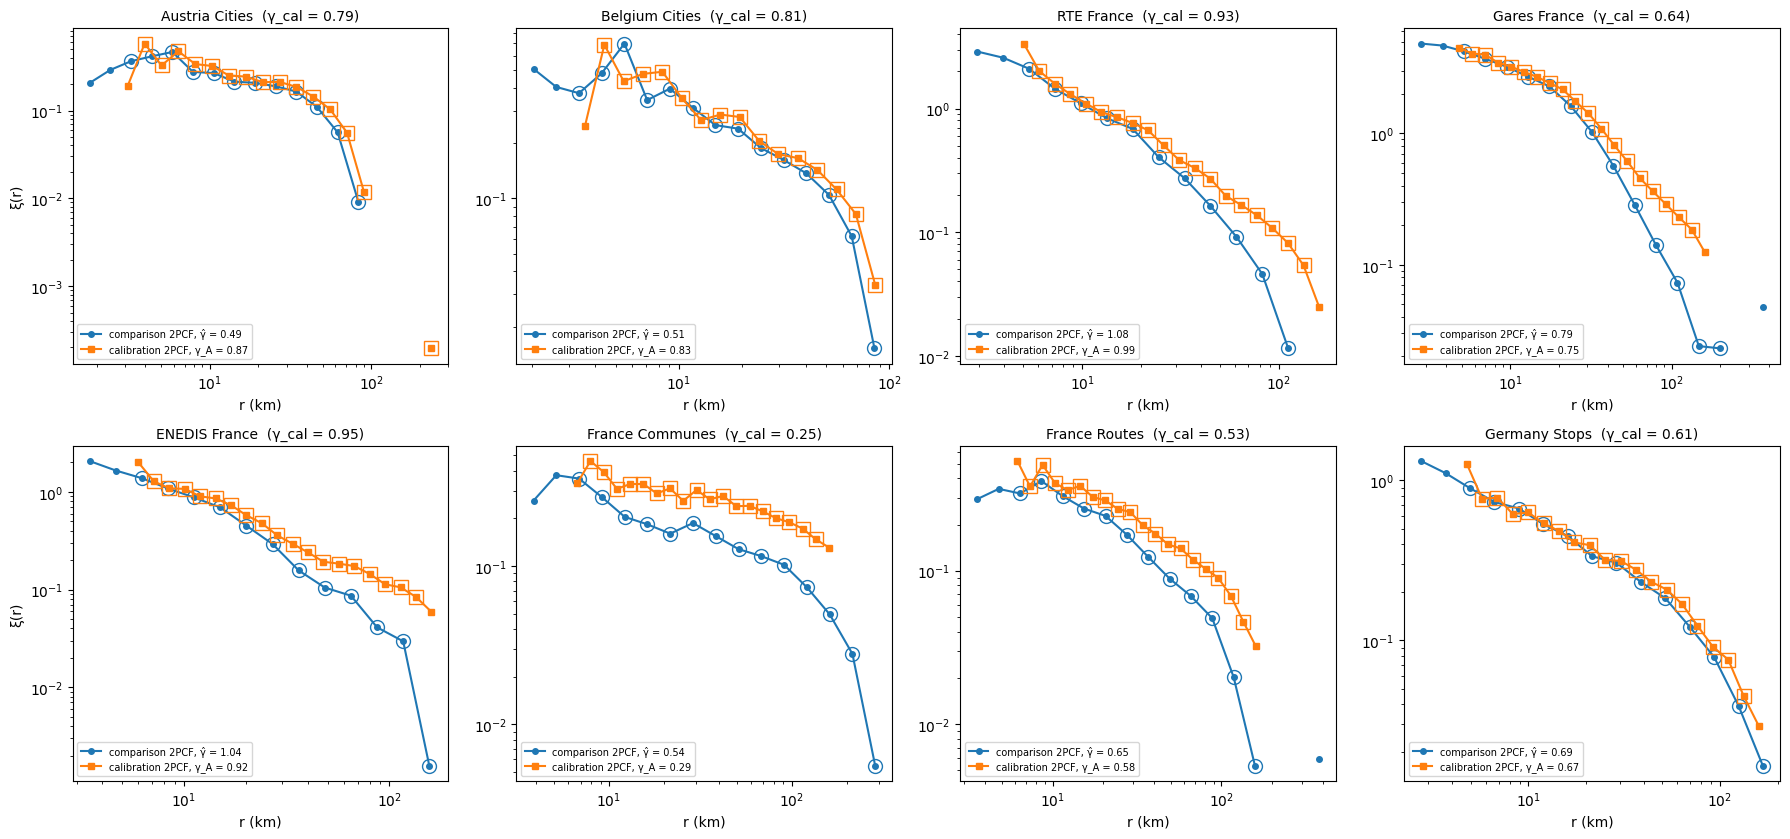

In [3]:
fig, axs = plt.subplots(2, 4, figsize=(18, 8.5))
for ax, name in zip(axs.ravel(), names):
    c = curves[name]
    pos = lambda x: np.where(x > 0, x, np.nan)
    ax.loglog(c["r_B"], pos(c["xi_B"]), "o-", c="C0", ms=4,
              label=f"comparison 2PCF, γ̂ = {tab.loc[name, 'gamma_hat']:.2f}")
    ax.loglog(c["r_B"][2:-2], pos(c["xi_B"][2:-2]), "o", mfc="none", ms=10, c="C0")
    ax.loglog(c["r_A"], pos(c["xi_A"]), "s-", c="C1", ms=4,
              label=f"calibration 2PCF, γ_A = {tab.loc[name, 'gamma_A_extract']:.2f}")
    a, b = cal.FIT_RANGE
    ax.loglog(c["r_A"][a:b], pos(c["xi_A"][a:b]), "s", mfc="none", ms=10, c="C1")
    ax.set_title(f"{name}  (γ_cal = {tab.loc[name, 'gamma_cal']:.2f})", fontsize=10)
    ax.set_xlabel("r (km)")
    ax.legend(fontsize=7, loc="lower left")
axs[0, 0].set_ylabel("ξ(r)")
axs[1, 0].set_ylabel("ξ(r)")
fig.tight_layout()
fig.savefig(OUT / "10_two_estimators.pdf", bbox_inches="tight")
plt.show()

The 2PCFs bend down at large r before the zero crossing, so a single exponent depends
on the window. On the French sets the comparison window goes beyond 160 km and includes
part of the drop, so γ̂ > γ_A. On the city catalogues it starts below the mean NN
distance, where ξ is flat, so γ̂ < γ_A. The vertical offset comes from the position of
ξ in the bin (upper edge against geometric centre) and moves r0, not γ.

## 3. Exponent of the mixture with the comparison settings

Mixture of notebook 07 with 5 seeds, γ̂ measured on each. Variant: λ set from γ̂
instead of γ_cal.

In [4]:
mix_rows = []
for name in names:
    ds, ld, N, xy_d, r_d, xi_d, g_hat = loaded[name]
    for label, gam in [("gamma_cal", ds["gamma_data"]), ("gamma_hat", g_hat)]:
        dsx = dict(ds, gamma_data=float(gam))
        for s in SEEDS:
            xy = su.build_sp_mixture(dsx, ld["gdf_edge"], ld["bounds"], ld["geom_norm"],
                                     r_d, xi_d, N, seed=s)
            r_m, xi_m = su.compute_2pcf_norm(xy, ld["geom_norm"])
            mix_rows.append(dict(
                dataset=name, lambda_from=label, seed=s,
                gamma_mix=su.fit_powerlaw_norm(r_m, xi_m)[0],
                jsd_2pcf=su.js_divergence(r_d, xi_d, r_m, xi_m),
                jsd_nn=su.nn_comparison(xy_d, {"SP": xy})[1]["SP"]))
mix = pd.DataFrame(mix_rows)
agg = mix.groupby(["lambda_from", "dataset"]).agg(
    gamma_mix_mean=("gamma_mix", "mean"), gamma_mix_std=("gamma_mix", "std"),
    jsd_2pcf_mean=("jsd_2pcf", "mean"), jsd_nn_mean=("jsd_nn", "mean"))
summary = tab[["gamma_cal", "gamma_A_extract", "gamma_A_std", "gamma_hat"]].join(
    agg.loc["gamma_cal"].add_suffix(" (λ from γ_cal)")).join(
    agg.loc["gamma_hat"].add_suffix(" (λ from γ̂)"))
pd.set_option("display.width", 250)
print(summary.round(4).to_string())
print("\nmean over datasets:")
print(summary.mean().round(4).to_string())
for col in ["jsd_2pcf_mean", "jsd_nn_mean"]:
    better = (summary[f"{col} (λ from γ_cal)"] < summary[f"{col} (λ from γ̂)"]).sum()
    print(f"{col}: λ from γ_cal is better on {better} of {len(summary)} datasets")

  L=12: 2,048 inside < 2,141, trying L=13


  L=12: 2,049 inside < 2,141, trying L=13
  L=13: 1,123 inside < 2,141, trying L=14


  L=12: 1,942 inside < 2,141, trying L=13


  L=10: 452 inside < 718, trying L=11


  L=10: 438 inside < 718, trying L=11


  L=10: 656 inside < 718, trying L=11


... (10 outputs left out)

  L=4: 1,696 inside < 2,088, trying L=5


  L=4: 2,045 inside < 2,088, trying L=5


  L=4: 1,543 inside < 2,088, trying L=5


                 gamma_cal  gamma_A_extract  gamma_A_std  gamma_hat  gamma_mix_mean (λ from γ_cal)  gamma_mix_std (λ from γ_cal)  jsd_2pcf_mean (λ from γ_cal)  jsd_nn_mean (λ from γ_cal)  gamma_mix_mean (λ from γ̂)  gamma_mix_std (λ from γ̂)  jsd_2pcf_mean (λ from γ̂)  jsd_nn_mean (λ from γ̂)
dataset                                                                                                                                                                                                                                                                                              
Austria Cities       0.789           0.8741       0.0673     0.4936                         0.8242                        0.1182                        0.0004                      0.0254                      0.6973                     0.1582                     0.0005                   0.0106
Belgium Cities       0.808           0.8266       0.0374     0.5147                         0.9046                    

- λ from γ_cal: γ_mix is within 0.1 of γ̂ of the data on seven datasets. It is steeper
  on the Austrian (+0.33) and Belgian (+0.39) cities, where γ_cal is about 0.3 above γ̂,
  and the mixture inherits it. The spread over seeds is 0.08 to 0.19.
- λ from γ̂: the mixture overshoots where γ̂ is large (RTE 1.22 against 1.08, ENEDIS
  1.35 against 1.04). Both JSDs are lower with λ from γ_cal on five of the nine
  datasets. The mean 2PCF JSD is lower with λ from γ̂, only because of one Belgian
  realisation with λ from γ_cal (seed 45, JSD 0.051) linked to the fragile ρ
  (notebook 11). Without Belgium, λ from γ_cal is better.
- The calibration of the paper is kept. The gap γ_cal − γ̂ measures how much a single
  exponent depends on the fit window.

## 4. Ranks over 10 realisations

Table 2 uses one realisation of each model (seed 42). The cache also holds the mean JSD
over 10 independent realisations (`band_*`). For each dataset the models are ranked on
this mean, and the ranks are averaged over the datasets.

In [5]:
MODELS = ["SP", "Poisson", "LGCP", "Hawkes", "Cox Hawkes"]
single, band, nn = {}, {}, {}
for name in names:
    f = su.CACHE_DIR / f"{su.cache_slug(name)}.npz"
    if not f.exists():
        continue
    d = np.load(f, allow_pickle=True)
    single[name] = {m: float(d[f"{m}_jsd"]) for m in MODELS}
    band[name] = {m: float(d[f"band_{m}_jsd_mean"]) for m in MODELS}
    nn[name] = {m: float(d[f"nn_jsd_{m}"]) for m in MODELS}
if single:
    ranks = pd.DataFrame({
        "2PCF, one realisation (Table 2)": pd.DataFrame(single).T.rank(axis=1).mean(),
        "2PCF, mean of 10 realisations": pd.DataFrame(band).T.rank(axis=1).mean(),
        "NN distances, one realisation": pd.DataFrame(nn).T.rank(axis=1).mean(),
    })
    print(f"mean JSD rank over {len(single)} datasets (1 = best):")
    print(ranks.round(2).to_string())
    first = {k: int((pd.DataFrame(v).T.rank(axis=1)["SP"] == 1).sum())
             for k, v in [("one realisation", single), ("10 realisations", band)]}
    print("\nSP ranked first on the 2PCF:", first)
else:
    print("no cache found, run scripts/compute_all.py first")

mean JSD rank over 9 datasets (1 = best):
            2PCF, one realisation (Table 2)  2PCF, mean of 10 realisations  NN distances, one realisation
SP                                     1.78                           2.22                           2.33
Poisson                                4.56                           3.78                           3.89
LGCP                                   2.78                           2.44                           2.67
Hawkes                                 2.67                           4.11                           4.00
Cox Hawkes                             3.22                           2.44                           2.11

SP ranked first on the 2PCF: {'one realisation': 5, '10 realisations': 4}


In [6]:
out = summary.copy()
out.to_csv(OUT / "10_gamma_consistency.csv")
mix.to_csv(OUT / "10_mixture_realisations.csv", index=False)
print("written: out/10_gamma_consistency.csv, out/10_mixture_realisations.csv")

written: out/10_gamma_consistency.csv, out/10_mixture_realisations.csv


## Results

| mean rank | 2PCF, one realisation (Table 2) | 2PCF, mean of 10 | NN, one realisation |
|---|---|---|---|
| SP | 1.78 | 2.22 | 2.33 |
| Hawkes | 2.67 | 4.11 | 4.00 |
| LGCP | 2.78 | 2.44 | 2.67 |
| Cox-Hawkes | 3.22 | 2.44 | 2.11 |
| Poisson | 4.56 | 3.78 | 3.89 |

- The SP keeps the best mean rank on the 2PCF over 10 realisations, but the lead shrinks
  (first on 4 datasets instead of 5). Hawkes falls back, since some of its realisations
  are far from the data.
- The gap between γ_cal and γ̂ comes from the estimator settings (window, bins,
  weights), not from the extract. It is largest on the two city catalogues and the
  municipalities.